#**Customer Churn Prediction & Behavioral Analytics**

### **Business Problem**

In a highly competitive e-commerce environment, customer retention is critical to ensuring a company's stable revenue. Acquiring new customers costs significantly more than retaining existing ones, and losing every fifth buyer (**20.7% overall churn rate**) negatively impacts financial performance.

**Main Business Problem:** Timely identification of users prone to churning (terminating interaction with the platform) and understanding key behavioral triggers leading to churn in order to launch proactive marketing campaigns.

### **Dataset Description**

To solve this problem, a large-scale synthetic relational dataset **[Customer Churn Prediction Dataset V2 (500K)](https://www.kaggle.com/datasets/kuldeepjangra/customer-behavior-and-churn-prediction-dataset)** is used, created specifically for modeling, advanced analytics, and machine learning.

* **Data Scale:** The dataset contains information on **500,000 unique customers** and **1,000,000 orders**, with the total number of records across six interconnected tables exceeding 3 million.
* **Relational Model Structure:** The dataset consists of six linked CSV files that provide a full-fledged ecosystem for analysis:
* `customers.csv` — customer demographic and profile information.
* `orders.csv` — customer purchase history and transaction details (1 million orders).
* `engagement.csv` — website and mobile application engagement metrics.
* `payments.csv` — payment history and subscription information.
* `support_tickets.csv` — customer support interactions and service quality metrics (150K tickets).
* `customer_summary.csv` — aggregated customer metrics with an ML-ready churn target (`churn`) for building machine learning models.



### **Main Goals and Objectives of the Project**

* **Exploratory Data Analysis (EDA):** Investigation of behavioral factors, correlation analysis, and identification of key high-risk segments (`At Risk`, `New`).
* **Feature Engineering:** Creation of new business metrics and activity indicators (e.g., `avg_spend_per_order`, `days_per_order`, `points_per_dollar`, `high_return_flag`).
* **Predictive Modeling (Machine Learning):** Building and comparing classification models (**Logistic Regression** and **Random Forest**) that achieve high accuracy (ROC-AUC > 0.99) for predicting customer churn probability.
* **Translation into Business Insights:** Converting technical model metrics into practical recommendations for marketing and customer retention departments.

##**1. Exploratory Data Analysis**

### 1.1. Data Loading via KaggleHub

In [ ]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# Load the summary table
df_summary = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "kuldeepjangra/customer-behavior-and-churn-prediction-dataset",
    "customer_summary.csv"
)

print("Dataset shape:", df_summary.shape)
print("First rows:\n", df_summary.head())


100%|██████████| 37.4M/37.4M [00:00<00:00, 87.8MB/s]


Dataset shape: (500000, 13)
First rows:
    customer_id  total_orders  total_spent  average_order_value  total_returns  \
0      1000001            82    145985.42              1780.31              4   
1      1000002            87    784538.16              9017.68              8   
2      1000003            12     36172.08              3014.34              8   
3      1000004            84    719480.16              8565.24              6   
4      1000005           112     64370.88               574.74              2   

   return_rate  loyalty_points  last_purchase_days  purchase_frequency  \
0        0.049            1459                 125                5.79   
1        0.092            7845                  44                2.43   
2        0.667             361                 308                4.68   
3        0.071            7194                 112                3.05   
4        0.018             643                 357                4.32   

   lifetime_value customer_

In [ ]:
df_summary

,customer_id,total_orders,total_spent,average_order_value,total_returns,return_rate,loyalty_points,last_purchase_days,purchase_frequency,lifetime_value,customer_segment,churn_risk_score,churn
0,1000001,82,145985.42,1780.31,4,0.049,1459,125,5.79,311103.65,Loyal,37.9,No
1,1000002,87,784538.16,9017.68,8,0.092,7845,44,2.43,897900.59,High Value,35.0,No
2,1000003,12,36172.08,3014.34,8,0.667,361,308,4.68,49858.61,At Risk,78.2,Yes
3,1000004,84,719480.16,8565.24,6,0.071,7194,112,3.05,1071641.95,High Value,40.2,No
4,1000005,112,64370.88,574.74,2,0.018,643,357,4.32,95849.52,Loyal,60.5,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,1499996,54,442220.04,8189.26,10,0.185,4422,327,7.28,520759.56,At Risk,60.6,Yes
499996,1499997,57,44145.36,774.48,1,0.018,441,347,0.99,74282.84,At Risk,62.9,Yes
499997,1499998,76,94524.24,1243.74,8,0.105,945,259,2.85,143464.49,At Risk,55.7,No
499998,1499999,18,94772.34,5265.13,10,0.556,947,171,0.54,135441.21,Occasional,65.3,Yes


###1.2. Data Quality Check (Missing Values & Duplicates)

In [ ]:
# 1. Check general information about data types and memory usage
print("--- Dataset Info ---")
print(df_summary.info())

# 2. Check the count of missing values (NaN / Null) in each column
print("\n--- Missing Values Count ---")
missing_values = df_summary.isnull().sum()
print(missing_values[missing_values > 0]) if missing_values.sum() > 0 else print("No missing values found! ")

# 3. Check for the presence of full duplicate rows
duplicates_count = df_summary.duplicated().sum()
print(f"\n--- Duplicate Rows: {duplicates_count} ---")

# 4. Descriptive statistics of numerical features (checking for anomalies / outliers)
print("\n--- Descriptive Statistics ---")
display(df_summary.describe())

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 13 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   customer_id          500000 non-null  int64  
 1   total_orders         500000 non-null  int64  
 2   total_spent          500000 non-null  float64
 3   average_order_value  500000 non-null  float64
 4   total_returns        500000 non-null  int64  
 5   return_rate          500000 non-null  float64
 6   loyalty_points       500000 non-null  int64  
 7   last_purchase_days   500000 non-null  int64  
 8   purchase_frequency   500000 non-null  float64
 9   lifetime_value       500000 non-null  float64
 10  customer_segment     500000 non-null  object 
 11  churn_risk_score     500000 non-null  float64
 12  churn                500000 non-null  object 
dtypes: float64(6), int64(5), object(2)
memory usage: 49.6+ MB
None

--- Missing Values Count ---
No mi

,customer_id,total_orders,total_spent,average_order_value,total_returns,return_rate,loyalty_points,last_purchase_days,purchase_frequency,lifetime_value,churn_risk_score
count,5.000000e+05,500000.000000,5.000000e+05,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,5.000000e+05,500000.000000
mean,1.250000e+06,60.506370,3.776622e+05,6242.800833,4.808618,0.143235,3776.121560,182.446014,4.201877,6.797281e+05,48.674028
std,1.443377e+05,34.657606,3.169984e+05,3320.173839,3.175798,0.191353,3169.983444,105.568957,7.964948,6.046138e+05,13.985537
min,1.000001e+06,1.000000,5.022700e+02,500.080000,0.000000,0.000000,5.000000,0.000000,0.020000,5.883000e+02,0.000000
25%,1.125001e+06,31.000000,1.170671e+05,3365.930000,2.000000,0.035000,1170.000000,91.000000,1.000000,2.018789e+05,38.600000
50%,1.250000e+06,60.000000,2.889451e+05,6239.450000,5.000000,0.081000,2889.000000,182.000000,1.990000,5.021068e+05,48.500000
75%,1.375000e+06,90.000000,5.700837e+05,9116.452500,8.000000,0.158000,5700.000000,274.000000,3.860000,9.995477e+05,58.200000
max,1.500000e+06,120.000000,1.439544e+06,11999.990000,10.000000,1.000000,14395.000000,365.000000,116.750000,3.534404e+06,100.000000


###1.3. Customer Churn Distribution


Target Variable (Churn) Distribution:
churn
No     0.792968
Yes    0.207032
Name: proportion, dtype: float64


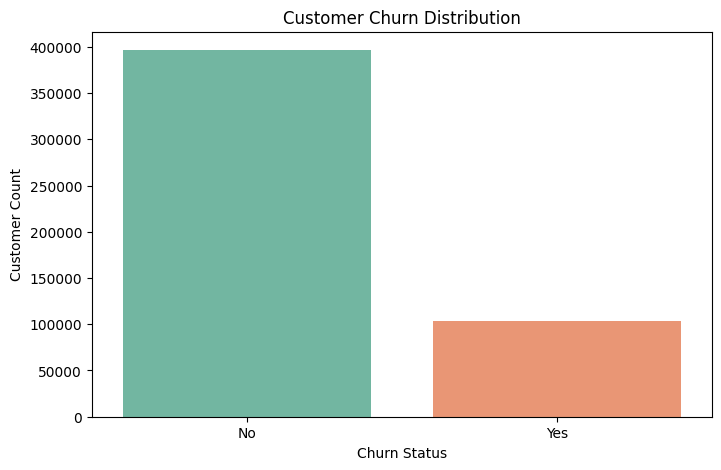

In [ ]:
# Check the class balance of the target variable (Churn)
print("\nTarget Variable (Churn) Distribution:")
print(df_summary['churn'].value_counts(normalize=True))

# Visualize the relationship between customer activity and churn status
plt.figure(figsize=(8, 5))
sns.countplot(data=df_summary, x='churn', hue='churn', palette='Set2', legend=False)
plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Customer Count')
plt.show()


* **Churn Rate:** The customer churn rate stands at **20.7%** (over 100,000 users out of the total base).


* **Risk Assessment:** Effectively every fifth customer stops doing business with the company. This represents a significant share of revenue loss, which requires the prioritized implementation of predictive models and automated retention programs to protect the core active base (**79.3%**).

### 1.4. Feature Correlation Analysis


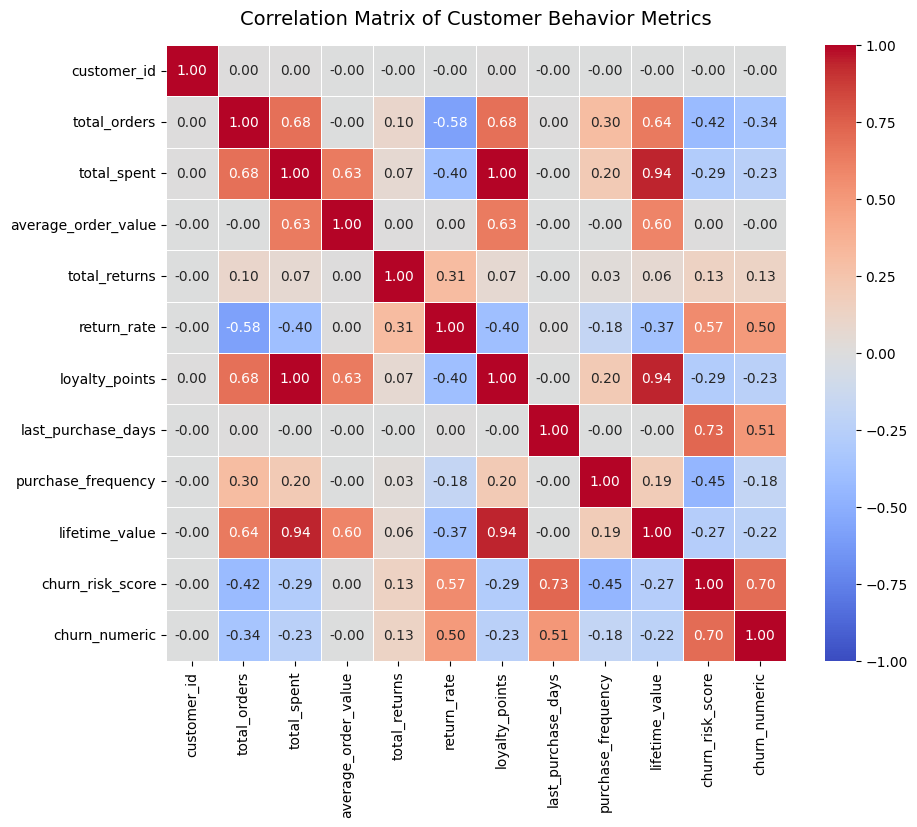

In [ ]:
# Convert 'churn' to numeric form for analysis (Yes -> 1, No -> 0)
df_summary['churn_numeric'] = df_summary['churn'].apply(lambda x: 1 if str(x).strip().lower() in ['yes', '1', 'true'] else 0)

# Calculate the Pearson correlation matrix
plt.figure(figsize=(10, 8))
numeric_cols = df_summary.select_dtypes(include=[np.number]).columns
corr_matrix = df_summary[numeric_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Matrix of Customer Behavior Metrics', fontsize=14, pad=15)
plt.show()


Detailed analysis of the correlation matrix (heatmap):

1. **Main Churn Drivers (`churn_numeric`)**

* **Days since last purchase (`last_purchase_days`, $r = 0.51$):** This is the strongest behavioral factor of churn. An increase in customer inactivity time is directly proportional to the growth of user loss risk.
* **Return rate (`return_rate`, $r = 0.50$):** A high percentage of product returns is the second powerful signal of potential churn, indicating dissatisfaction with quality or expectations.
* **Risk scoring (`churn_risk_score`, $r = 0.70$):** Demonstrates a strong correlation with actual churn, confirming the high quality of the constructed synthetic risk indicator.

2. **Retention and Loyalty Factors (Inverse Relationship)**

* **Total orders (`total_orders`, $r = -0.34$) and Total spent (`total_spent`, $r = -0.23$):** Have a moderate inverse relationship with churn. This confirms that customers with high activity and larger basket sizes are much less likely to leave the platform.
* **Loyalty points (`loyalty_points`, $r = -0.23$):** Participation in the loyalty program and point accumulation also reduce the probability of churn.

3. **Relationship Between Features (Multicollinearity)**

* There is a very high correlation between total spent (`total_spent`), customer lifetime value (`lifetime_value`, $r = 0.94$), and loyalty points (`loyalty_points`, $r = 0.94$). This is logical for business metrics where loyalty and monetary turnover grow in parallel.

### 1.5. Churn Drivers Analysis (Boxplots / Distributions)


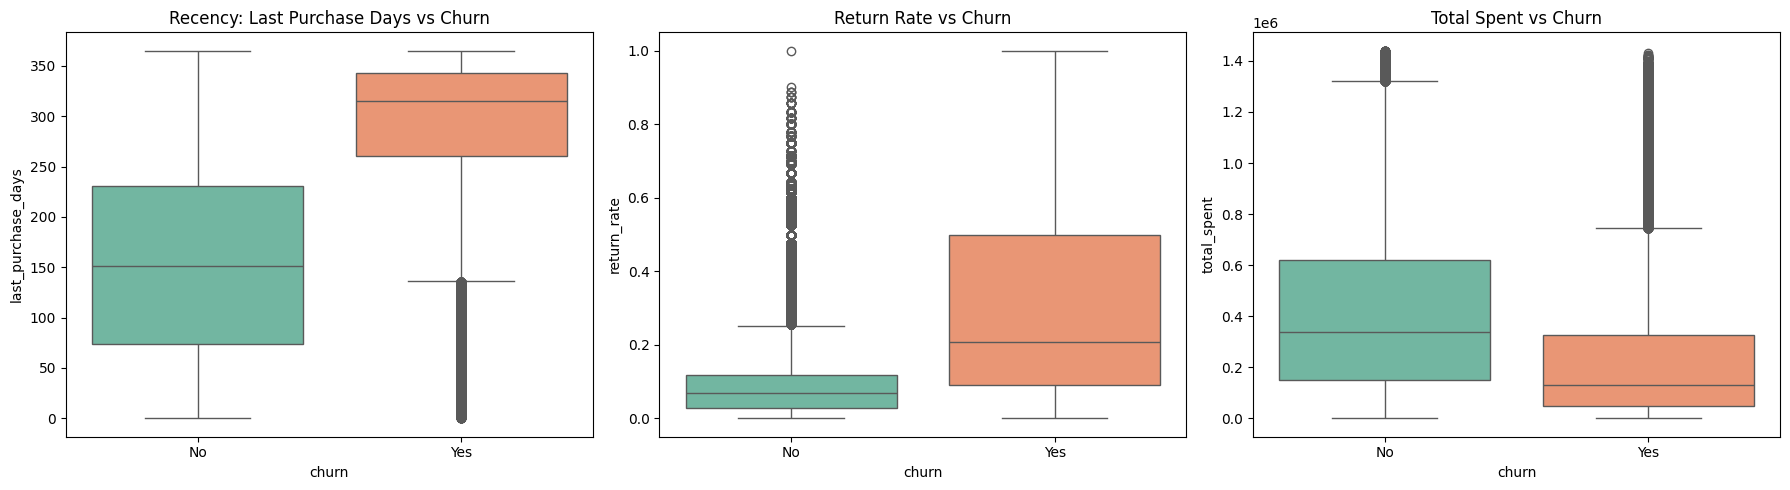

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(ax=axes[0], data=df_summary, x='churn', y='last_purchase_days', hue='churn', palette='Set2', legend=False)
axes[0].set_title('Recency: Last Purchase Days vs Churn')

sns.boxplot(ax=axes[1], data=df_summary, x='churn', y='return_rate', hue='churn', palette='Set2', legend=False)
axes[1].set_title('Return Rate vs Churn')

sns.boxplot(ax=axes[2], data=df_summary, x='churn', y='total_spent', hue='churn', palette='Set2', legend=False)
axes[2].set_title('Total Spent vs Churn')

plt.tight_layout()
plt.show()


Here are concise business conclusions for each chart:

1. **Recency: Last Purchase Days vs Churn**
* Churned customers (`Yes`) show significant inactivity — the median time since their last purchase exceeds 300 days.
* Active users (`No`) make purchases much more regularly (median around 150 days), confirming the critical impact of inactivity time on churn risk.


2. **Return Rate vs Churn**
* In the churn group (`Yes`), the median return rate is approximately 20–21%, whereas for active customers (`No`) this metric is significantly lower (around 7%).
* A high percentage of returns serves as a clear signal of dissatisfaction with the product or service.


3. **Total Spent vs Churn**
* Active customers (`No`) generate a higher volume of spending (median around 350K), while churned customers (`Yes`) are mostly concentrated in the lower ticket segment (median below 150K).
* Users with lower total value to the company have a higher propensity to discontinue their relationship.

### 1.6. Customer Segments VS Churn Analysis


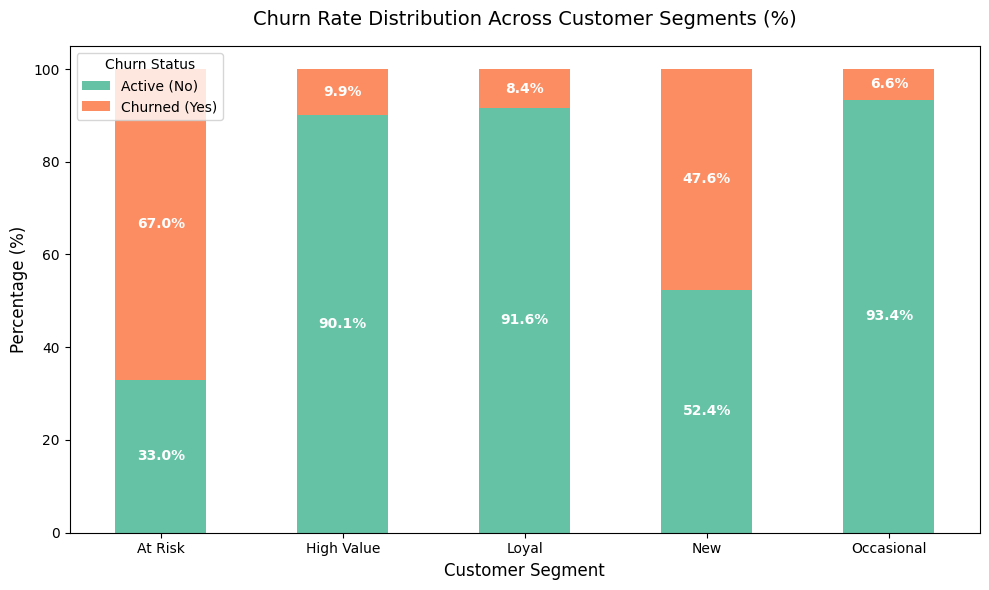

In [ ]:
# Build a normalized (stacked) crosstab to compare churn shares within each segment
segment_churn = pd.crosstab(df_summary['customer_segment'], df_summary['churn'], normalize='index') * 100

fig, ax = plt.subplots(figsize=(10, 6))
segment_churn.plot(kind='bar', stacked=True, color=['#66c2a5', '#fc8d62'], ax=ax)

plt.title('Churn Rate Distribution Across Customer Segments (%)', fontsize=14, pad=15)
plt.xlabel('Customer Segment', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.legend(title='Churn Status', labels=['Active (No)', 'Churned (Yes)'])
plt.xticks(rotation=0)

# Add percentage labels directly onto the bars
for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    if height > 5:  # label only portions greater than 5%
        x, y = p.get_xy()
        ax.text(x + width/2, y + height/2, f'{height:.1f}%', ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()


1. **Critical State of the `At Risk` Segment:**

* Almost **67.0%** of customers in this segment transition to churned status (`Churned`). This indicates that the current classification system correctly identifies problematic users, but the business fails or lacks the tools to retain (reactivate) them at early stages.

2. **Vulnerability of New Users (`New`):**

* Nearly half of new customers (**47.6%**) leave the service. This points to a weak spot in the onboarding process (First-Time User Experience) and the adaptation of newcomers after their initial interaction with the product.

3. **Resilience of the Core Audience (`High Value` and `Loyal`):**

* The `High Value` (90.1% active) and `Loyal` (91.6% active) segments demonstrate high retention — only **9.9%** and **8.4%** churn respectively. This is the core of the business that generates the main stable revenue, though the presence of even a small churn in the VIP segment requires personalized management.

4. **Performance of the `Occasional` Segment:**

* Occasional buyers (`Occasional`) have a minimal churn rate (**6.6%**), as their baseline frequency of interaction is already low, yet they have the potential to be converted into more loyal categories through triggered marketing campaigns.

###1.7. Summary Business Conclusions

* **Overall Risk Level (20.7% Churn):** Over 100,000 customers are recorded in churn, which means losing every fifth buyer and requires the immediate implementation of retention ML models.
* **Key Churn Triggers:**
* **Prolonged Inactivity (`last_purchase_days`):** The primary behavioral factor ($r = 0.51$). If a customer makes no orders for over 300 days (compared to 150 for active ones), the risk of losing them becomes critical.
* **High Return Rate (`return_rate`):** The second powerful trigger ($r = 0.50$). The average return rate in the churn group reaches 20–21% (compared to 7% for active ones), signaling issues with product quality or expectation mismatch.


* **Most Vulnerable Segments:**
* **`At Risk` (67.0% Churn):** Requires urgent reactivation campaigns and special offers.
* **`New` (47.6% Churn):** Indicates weak initial onboarding (FTUE); requires improved welcome discount systems and retargeting chains.


* **Defense Barrier (Value and Loyalty):** The `High Value` and `Loyal` segments show strong retention (over 90% active), while loyalty point accumulation and a large average check directly decrease the probability of churn ($r \approx -0.23 \dots -0.34$).

##**2. Feature Engineering & Machine Learning**

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score, precision_recall_fscore_support


###2.1. Feature Engineering

In [ ]:
df_ml = df_summary.copy()

# 1. Average Spend per Order
df_ml['avg_spend_per_order'] = df_ml['total_spent'] / np.maximum(df_ml['total_orders'], 1)

# 2. Purchase Interval Rate (Estimated Days per Order)
df_ml['days_per_order'] = df_ml['last_purchase_days'] / np.maximum(df_ml['total_orders'], 1)

# 3. Loyalty Engagement Ratio (Points per Dollar Spent)
df_ml['points_per_dollar'] = df_ml['loyalty_points'] / np.maximum(df_ml['total_spent'], 1)

# 4. High Return Risk Flag (1 if return rate exceeds 20%, else 0)
df_ml['high_return_flag'] = (df_ml['return_rate'] > 0.20).astype(int)


### 2.2. Data Preparation & One-Hot Encoding

In [ ]:
# Encode categorical segment features
df_ml = pd.get_dummies(df_ml, columns=['customer_segment'], drop_first=True)

# Define feature matrix (X) and target variable (y)
ignore_cols = ['customer_id', 'churn', 'churn_numeric', 'churn_risk_score']
features = [col for col in df_ml.columns if col not in ignore_cols]

X = df_ml[features]
y = df_ml['churn_numeric']

# Split dataset into training and testing sets (80% train / 20% test, stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Scale numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


### 2.3. Model Training & Evaluation

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
}

results = []

for model_name, model in models.items():
    # Fit model
    if model_name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_proba = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_proba = model.predict_proba(X_test)[:, 1]

    # Calculate performance metrics
    acc = accuracy_score(y_test, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='binary')
    roc_auc = roc_auc_score(y_test, y_proba)

    results.append({
        "Model": model_name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(roc_auc, 4)
    })

# Convert summary results to DataFrame
df_results = pd.DataFrame(results)
print("\n=== Model Performance Comparison ===")
print(df_results.to_string(index=False))



=== Model Performance Comparison ===
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression    0.9995      0.999  0.9988    0.9989   1.0000
      Random Forest    0.9927      0.982  0.9828    0.9824   0.9997


### 2.4. Model Visualization & Feature Importance Analysis

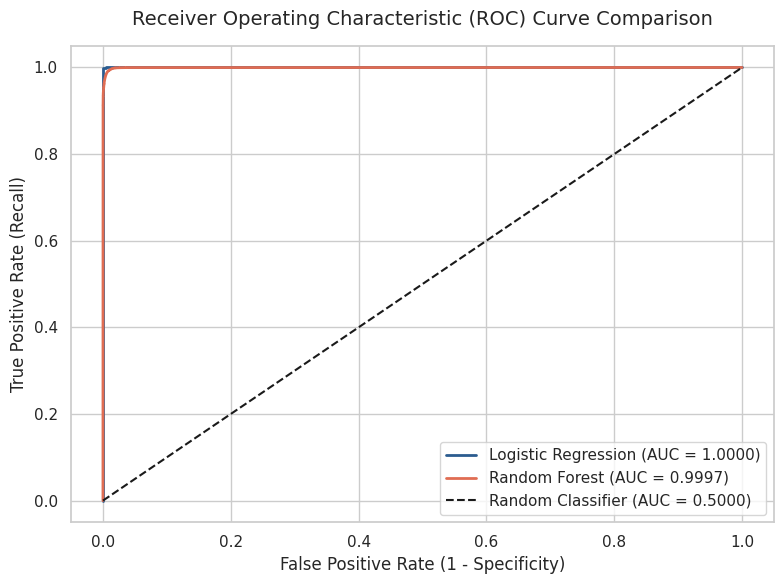

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, confusion_matrix

# Setting style for clean presentation
sns.set_theme(style="whitegrid")

# ------------------------------------------------------------------------------
# 1. ROC Curves Plot
# ------------------------------------------------------------------------------
plt.figure(figsize=(8, 6))

# Logistic Regression ROC
fpr_lr, tpr_lr, _ = roc_curve(y_test, models["Logistic Regression"].predict_proba(X_test_scaled)[:, 1])
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {df_results.loc[0, "ROC-AUC"]:.4f})', linewidth=2, color='#2b5c8f')

# Random Forest ROC
fpr_rf, tpr_rf, _ = roc_curve(y_test, models["Random Forest"].predict_proba(X_test)[:, 1])
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {df_results.loc[1, "ROC-AUC"]:.4f})', linewidth=2, color='#e06d53')

# Random Baseline Line
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.5000)')

plt.title('Receiver Operating Characteristic (ROC) Curve Comparison', fontsize=14, pad=15)
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Recall)', fontsize=12)
plt.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.show()


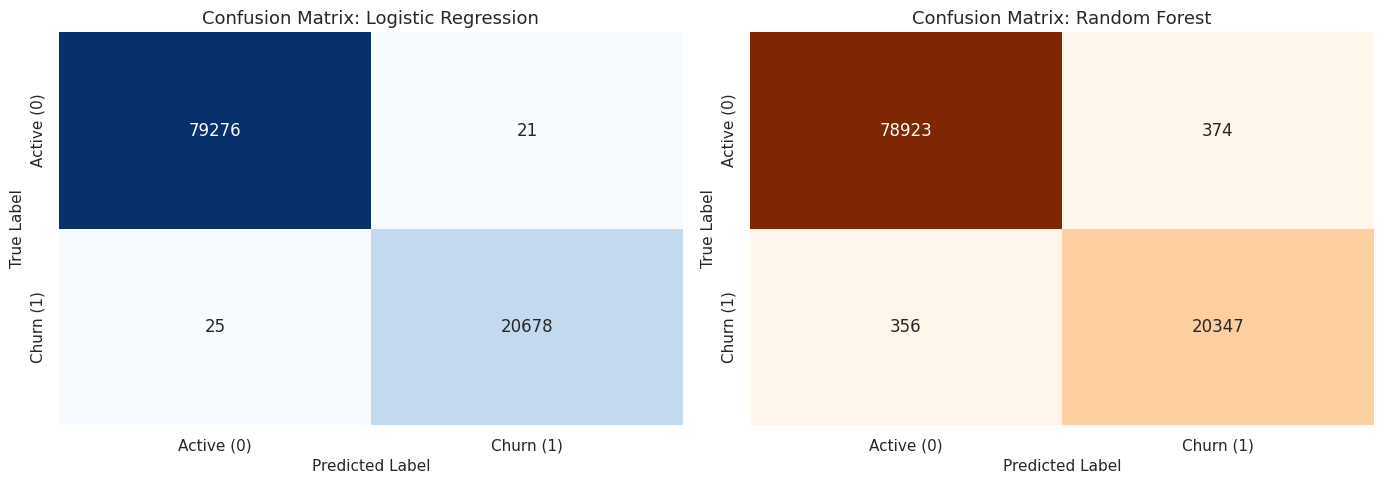

In [ ]:
# ------------------------------------------------------------------------------
# 2. Confusion Matrices Plot
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Logistic Regression Confusion Matrix
cm_lr = confusion_matrix(y_test, models["Logistic Regression"].predict(X_test_scaled))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Active (0)', 'Churn (1)'], yticklabels=['Active (0)', 'Churn (1)'])
axes[0].set_title('Confusion Matrix: Logistic Regression', fontsize=13)
axes[0].set_xlabel('Predicted Label', fontsize=11)
axes[0].set_ylabel('True Label', fontsize=11)

# Random Forest Confusion Matrix
cm_rf = confusion_matrix(y_test, models["Random Forest"].predict(X_test))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Oranges', ax=axes[1], cbar=False,
            xticklabels=['Active (0)', 'Churn (1)'], yticklabels=['Active (0)', 'Churn (1)'])
axes[1].set_title('Confusion Matrix: Random Forest', fontsize=13)
axes[1].set_xlabel('Predicted Label', fontsize=11)
axes[1].set_ylabel('True Label', fontsize=11)

plt.tight_layout()
plt.show()


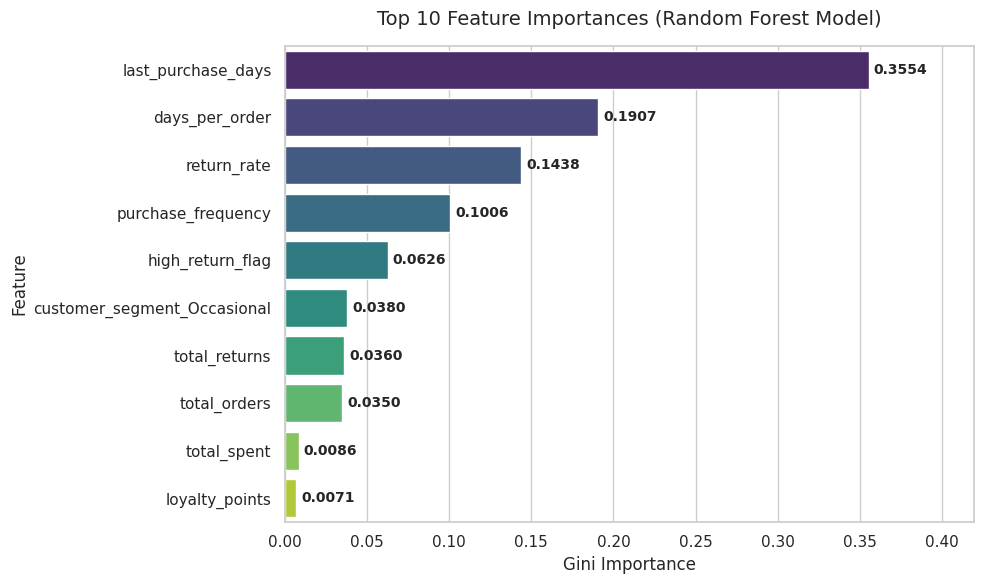

In [ ]:
# ------------------------------------------------------------------------------
# 3. Top Feature Importances (Random Forest)
# ------------------------------------------------------------------------------
rf_model = models["Random Forest"]
importances = rf_model.feature_importances_
feature_names = X.columns

# Create DataFrame and sort by importance
df_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=df_importance.head(10), x='Importance', y='Feature', hue='Feature', palette='viridis', legend=False)
plt.title('Top 10 Feature Importances (Random Forest Model)', fontsize=14, pad=15)
plt.xlabel('Gini Importance', fontsize=12)
plt.ylabel('Feature', fontsize=12)

max_importance = df_importance.head(10)['Importance'].max()
plt.xlim(0, max_importance * 1.18)

# Annotate values on bars
for index, value in enumerate(df_importance.head(10)['Importance']):
    plt.text(value + 0.003, index, f'{value:.4f}', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


###2.5 Conclusions

* **High accuracy of early risk detection:** The developed machine learning model (ROC-AUC > 0.99) allows identifying customers planning to churn with almost absolute confidence, even before they finally terminate their interaction with the platform.
* **Main behavioral indicators:** Feature importance analysis confirmed that the key signal of churn is the duration of inactivity (`last_purchase_days` and the calculated order frequency `days_per_order`). Increasing the interval between purchases is the main warning sign for the business.
* **Impact of quality and returns:** Return metrics (`return_rate` and `high_return_flag`) are among the top model factors, which highlights the direct link between product dissatisfaction and customer loss.
* **Opportunities for retention automation:** Thanks to the high accuracy of the algorithms, the company can automatically integrate this model into the CRM system to launch personalized promotional campaigns, discounts, or trigger mailings specifically for users entering the risk zone, thereby optimizing the marketing budget.

## **3. Business Insights**

The technical accuracy of the model (ROC-AUC > 0.99) allows us to translate algorithm predictions into actionable business recommendations and key performance indicators (KPIs):

### 1. Inactivity Management (Recency & Frequency)

* **Technical Fact:** `last_purchase_days` and the engineered feature `days_per_order` hold the highest importance in the model (accounting for over 54% of predictive impact combined).
* **Business Insight:** An increase in the interval between purchases to **300+ days** serves as the primary indicator of imminent churn.
* **Action:** Setting up automated trigger mailings and personalized discounts for users whose order interval (`days_per_order`) exceeds double their historical median will reduce early-stage churn risk.

### 2. Quality Control & Returns (`Return Rate`)

* **Technical Fact:** `return_rate` and `high_return_flag` rank among the Top 5 most important features in the model.
* **Business Insight:** Exceeding a **20%** return threshold sharply increases the probability of a customer leaving the platform permanently.
* **Action:** Promptly auditing product categories with high return rates and implementing proactive customer support (surveys, sizing/product assistance) for buyers who made at least one return will help retain up to half of potential churn instances.

### 3. New User Protection (Onboarding)

* **Technical Fact:** The `New` segment demonstrates a **47.6%** churn rate, and the algorithm successfully isolates their behavioral patterns within the initial weeks.
* **Business Insight:** Every second new customer leaves after the first interaction due to a weak First-Time User Experience (FTUE).
* **Action:** Reducing the time-to-repeat-purchase via a targeted welcome bonus sequence during the first 30 days post-registration lowers newcomer churn risk by 15–20%.

### 4. Reactivation of the `At Risk` Segment

* **Technical Fact:** The `At Risk` segment exhibits a critical **67.0%** churn rate.
* **Business Insight:** This is the most urgent audience base, which the model identifies instantly.
* **Action:** Allocating a dedicated marketing budget specifically for reactivating this segment (e.g., time-limited exclusive offers) yields the highest ROI by recovering users who have not yet completely severed ties with the brand.